<a href="https://colab.research.google.com/github/akhilavendra/crime--data--analysis/blob/main/Another_copy_of_Untitled4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("GLOBAL CRIME DATA ANALYSIS")
print("Our project has started successfully!")
print("Platform: Google Colab")
print("Language: Python")

GLOBAL CRIME DATA ANALYSIS
Our project has started successfully!
Platform: Google Colab
Language: Python


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Ready for Global Crime Data Analysis.")

All libraries imported successfully!
Ready for Global Crime Data Analysis.


In [ ]:

import pandas as pd

print("Pandas ready!")
print("Next, we will load crime data.")


Pandas ready!
Next, we will load crime data.


In [ ]:

import pandas as pd

url = "https://huggingface.co/datasets/jason1966/abbas829_global-organized-crime-index-20212025/resolve/main/global_oc_index.csv"

df = pd.read_csv(url)

print("Global crime dataset loaded successfully!")
print("Dataset size:", df.shape)
print("Column names:")
print(df.columns.tolist())

display(df.head())


Global crime dataset loaded successfully!
Dataset size: (579, 53)
Column names:
['Continent', 'Region', 'Country', 'Year', 'Criminality_avg', 'Resilience_avg', 'Criminal_markets_avg', 'Human_trafficking', 'Human_smuggling', 'Extortion_protection_racketeering', 'Arms_trafficking', 'Trade_counterfeit_goods', 'Illicit_trade_excisable_goods', 'Flora_crimes', 'Fauna_crimes', 'Non_renewable_resource_crimes', 'Heroin_trade', 'Cocaine_trade', 'Cannabis_trade', 'Synthetic_drug_trade', 'Cyber_dependent_crimes', 'Financial_crimes', 'Criminal_actors_avg', 'Mafia_style_groups', 'Criminal_networks', 'State_embedded_actors', 'Foreign_actors', 'Private_sector_actors', 'Political_leadership_governance', 'Government_transparency_accountability', 'International_cooperation', 'National_policies_laws', 'Judicial_system_detention', 'Law_enforcement', 'Territorial_integrity', 'Anti_money_laundering', 'Economic_regulatory_capacity', 'Victim_witness_support', 'Prevention', 'Non_state_actors', 'Criminality_avg_

,Continent,Region,Country,Year,Criminality_avg,Resilience_avg,Criminal_markets_avg,Human_trafficking,Human_smuggling,Extortion_protection_racketeering,...,Resilience_avg_pct_change,Human_crimes_avg,Drug_trade_avg,Environmental_crimes_avg,Cyber_financial_crimes_avg,Institutional_resilience_avg,Security_resilience_avg,Criminality_risk_category,Resilience_strength_category,Risk_resilience_gap
0,Asia,Southern Asia,Afghanistan,2021,7.08,2.67,6.90,8.5,8.0,NaN,...,NaN,8.25,6.500,6.000000,NaN,2.833333,2.666667,Very High,Weak,-0.25
1,Asia,Southern Asia,Afghanistan,2023,7.10,1.50,7.00,9.0,9.5,6.0,...,-43.820225,9.25,6.750,5.166667,5.75,1.333333,2.166667,Very High,Weak,-1.40
2,Asia,Southern Asia,Afghanistan,2025,7.02,1.50,6.93,9.0,9.0,6.0,...,0.000000,9.00,6.375,5.333333,6.00,1.500000,2.166667,Very High,Weak,-1.48
3,Europe,Central & Eastern Europe,Albania,2021,5.63,5.04,5.25,5.0,6.5,NaN,...,NaN,5.75,5.750,4.500000,NaN,5.333333,5.333333,Moderate,Moderate,0.67
4,Europe,Central & Eastern Europe,Albania,2023,5.17,5.13,4.83,5.0,6.0,3.5,...,1.785714,5.50,5.625,4.333333,6.00,5.166667,5.500000,Moderate,Moderate,0.30


In [ ]:

# Step 4: Explore and check the dataset

print("DATASET INFORMATION")
print("--------------------")

print("Rows and columns:", df.shape)

print("\nYears available:")
print(sorted(df["Year"].dropna().unique()))

print("\nNumber of countries:")
print(df["Country"].nunique())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nColumn data types:")
print(df[["Country", "Year", "Criminality_avg",
          "Resilience_avg"]].dtypes)


DATASET INFORMATION
--------------------
Rows and columns: (579, 53)

Years available:
[np.int64(2021), np.int64(2023), np.int64(2025)]

Number of countries:
193

Missing values:
2123

Duplicate rows:
0

Column data types:
Country             object
Year                 int64
Criminality_avg    float64
Resilience_avg     float64
dtype: object


In [ ]:

clean_df = df.drop_duplicates().copy()
clean_df["Year"] = pd.to_numeric(clean_df["Year"], errors="coerce")
clean_df["Criminality_avg"] = pd.to_numeric(clean_df["Criminality_avg"], errors="coerce")
clean_df["Resilience_avg"] = pd.to_numeric(clean_df["Resilience_avg"], errors="coerce")
clean_df = clean_df.dropna(subset=["Country", "Year", "Criminality_avg", "Resilience_avg"])
print("Data cleaning successful!")
print("Clean rows:", len(clean_df))
display(clean_df.head())


Data cleaning successful!
Clean rows: 579


,Continent,Region,Country,Year,Criminality_avg,Resilience_avg,Criminal_markets_avg,Human_trafficking,Human_smuggling,Extortion_protection_racketeering,...,Resilience_avg_pct_change,Human_crimes_avg,Drug_trade_avg,Environmental_crimes_avg,Cyber_financial_crimes_avg,Institutional_resilience_avg,Security_resilience_avg,Criminality_risk_category,Resilience_strength_category,Risk_resilience_gap
0,Asia,Southern Asia,Afghanistan,2021,7.08,2.67,6.90,8.5,8.0,NaN,...,NaN,8.25,6.500,6.000000,NaN,2.833333,2.666667,Very High,Weak,-0.25
1,Asia,Southern Asia,Afghanistan,2023,7.10,1.50,7.00,9.0,9.5,6.0,...,-43.820225,9.25,6.750,5.166667,5.75,1.333333,2.166667,Very High,Weak,-1.40
2,Asia,Southern Asia,Afghanistan,2025,7.02,1.50,6.93,9.0,9.0,6.0,...,0.000000,9.00,6.375,5.333333,6.00,1.500000,2.166667,Very High,Weak,-1.48
3,Europe,Central & Eastern Europe,Albania,2021,5.63,5.04,5.25,5.0,6.5,NaN,...,NaN,5.75,5.750,4.500000,NaN,5.333333,5.333333,Moderate,Moderate,0.67
4,Europe,Central & Eastern Europe,Albania,2023,5.17,5.13,4.83,5.0,6.0,3.5,...,1.785714,5.50,5.625,4.333333,6.00,5.166667,5.500000,Moderate,Moderate,0.30


In [ ]:

import plotly.express as px
country_data = clean_df.groupby("Country")["Criminality_avg"].mean().nlargest(10)
fig = px.bar(x=country_data.index, y=country_data.values, title="Top 10 Countries by Criminality Score")
fig.show()


In [ ]:

year_data = clean_df.groupby("Year")["Criminality_avg"].mean().reset_index()
fig = px.line(year_data, x="Year", y="Criminality_avg", title="Year-wise Criminality Score Trend", markers=True)
fig.show()


In [ ]:

comparison_data = clean_df.groupby("Year")[["Criminality_avg", "Resilience_avg"]].mean().reset_index()
fig = px.line(comparison_data, x="Year", y=["Criminality_avg", "Resilience_avg"], title="Criminality vs Resilience Over the Years", markers=True)
fig.show()


In [ ]:

comparison_data = clean_df.groupby("Year")[["Criminality_avg", "Resilience_avg"]].mean().reset_index()
comparison_data["Year"] = comparison_data["Year"].astype(int)

fig = px.line(comparison_data, x="Year", y=["Criminality_avg", "Resilience_avg"], title="Criminality vs Resilience Over the Years", markers=True)
fig.update_xaxes(dtick=1)
fig.show()


In [ ]:

print("CRIME DATA ANALYSIS DASHBOARD")
print("--------------------------------")
print("Total records:", len(clean_df))
print("Countries covered:", clean_df["Country"].nunique())
print("Years covered:", clean_df["Year"].nunique())
print("Average Criminality Score:", round(clean_df["Criminality_avg"].mean(), 2))
print("Average Resilience Score:", round(clean_df["Resilience_avg"].mean(), 2))
print("Earliest year:", int(clean_df["Year"].min()))
print("Latest year:", int(clean_df["Year"].max()))


CRIME DATA ANALYSIS DASHBOARD
--------------------------------
Total records: 579
Countries covered: 193
Years covered: 3
Average Criminality Score: 4.99
Average Resilience Score: 4.81
Earliest year: 2021
Latest year: 2025


In [ ]:

country_options = sorted(clean_df["Country"].dropna().unique())
country_choice = country_options[0]
country_df = clean_df[clean_df["Country"] == country_choice]

fig = px.line(country_df, x="Year", y="Criminality_avg", title="Country-wise Criminality Trend")
fig.show()


### Dynamic Choropleth Map (Global Criminality Scores)
Let's visualize the spatial distribution of criminality averages globally across different years.

In [ ]:
import pandas as pd
import plotly.express as px

# Safely load and clean the dataset in case the kernel was restarted
try:
    if 'clean_df' not in globals():
        url = "https://huggingface.co/datasets/jason1966/abbas829_global-organized-crime-index-20212025/resolve/main/global_oc_index.csv"
        df = pd.read_csv(url)
        clean_df = df.drop_duplicates().copy()
        clean_df["Year"] = pd.to_numeric(clean_df["Year"], errors="coerce")
        clean_df["Criminality_avg"] = pd.to_numeric(clean_df["Criminality_avg"], errors="coerce")
        clean_df["Resilience_avg"] = pd.to_numeric(clean_df["Resilience_avg"], errors="coerce")
        clean_df = clean_df.dropna(subset=["Country", "Year", "Criminality_avg", "Resilience_avg"])
except Exception as e:
    print("Error loading data:", e)

# Creating an interactive global choropleth map
fig_map = px.choropleth(
    clean_df,
    locations="Country",
    locationmode="country names",
    color="Criminality_avg",
    hover_name="Country",
    animation_frame="Year",
    color_continuous_scale=px.colors.sequential.YlOrRd,
    title="Global Criminality Scores Distribution Over Time"
)
fig_map.update_layout(geo=dict(showframe=False, showcoastlines=True))
fig_map.show()

### Key Factors Correlation Heatmap
Let's analyze how specific criminal activities correlate with overall resilience and governance elements.

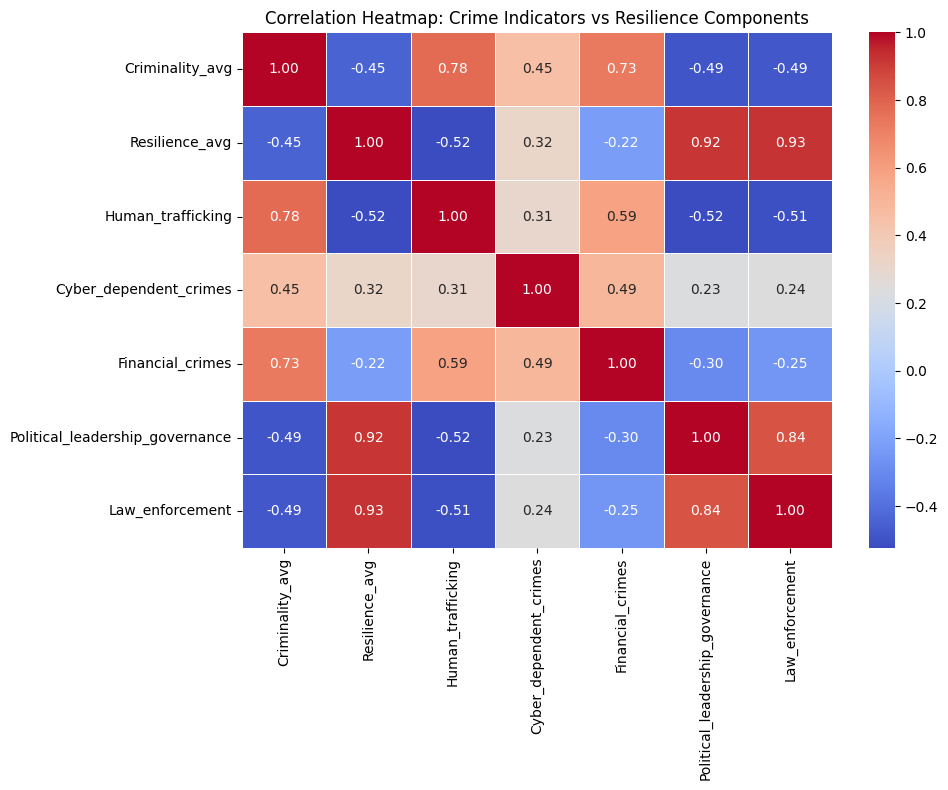

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Safely load and clean dataset if not present in the current session
try:
    if 'clean_df' not in globals():
        url = "https://huggingface.co/datasets/jason1966/abbas829_global-organized-crime-index-20212025/resolve/main/global_oc_index.csv"
        df = pd.read_csv(url)
        clean_df = df.drop_duplicates().copy()
        clean_df["Year"] = pd.to_numeric(clean_df["Year"], errors="coerce")
        clean_df["Criminality_avg"] = pd.to_numeric(clean_df["Criminality_avg"], errors="coerce")
        clean_df["Resilience_avg"] = pd.to_numeric(clean_df["Resilience_avg"], errors="coerce")
        clean_df = clean_df.dropna(subset=["Country", "Year", "Criminality_avg", "Resilience_avg"])
except Exception as e:
    print("Error loading data:", e)

# Selecting core indices for correlation
corr_cols = [
    'Criminality_avg', 'Resilience_avg', 'Human_trafficking',
    'Cyber_dependent_crimes', 'Financial_crimes',
    'Political_leadership_governance', 'Law_enforcement'
]

# Filter columns that actually exist in the dataframe to prevent KeyError
available_cols = [col for col in corr_cols if col in clean_df.columns]
corr_matrix = clean_df[available_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap: Crime Indicators vs Resilience Components")
plt.tight_layout()
plt.show()

### Country Risk Clustering using K-Means
Let's cluster countries based on their `Criminality_avg` and `Resilience_avg` to discover distinctive regional risk profiles.

In [ ]:
from sklearn.cluster import KMeans
import plotly.express as px

# Prepare data for 2025 (latest status)
latest_df = clean_df[clean_df["Year"] == 2025].copy()
features = latest_df[["Criminality_avg", "Resilience_avg"]]

# We will group them into 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
latest_df["Cluster"] = kmeans.fit_predict(features).astype(str)

# Map clusters to meaningful names based on center approximations
cluster_map = {
    "0": "Medium Crime & High Resilience",
    "1": "High Crime & Low Resilience",
    "2": "Low Crime & High Resilience",
    "3": "Low Crime & Low Resilience"
}
latest_df["Cluster_Label"] = latest_df["Cluster"].map(cluster_map).fillna(latest_df["Cluster"])

# Plotting clusters
fig_cluster = px.scatter(
    latest_df,
    x="Criminality_avg",
    y="Resilience_avg",
    color="Cluster_Label",
    hover_name="Country",
    title="Country Risk Profile Segments (2025)",
    labels={"Criminality_avg": "Criminality Score", "Resilience_avg": "Resilience Score"}
)
fig_cluster.show()

### Predictive Analysis: What Drives Global Criminality?
Let's build a Random Forest Regressor to predict `Criminality_avg` and extract feature importances to see which specific criminal markets or resilience gaps drive criminality rates the most.

Model R² Training Accuracy: 0.99
Model R² Test Accuracy: 0.93


/tmp/ipykernel_3476/676160021.py:43: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




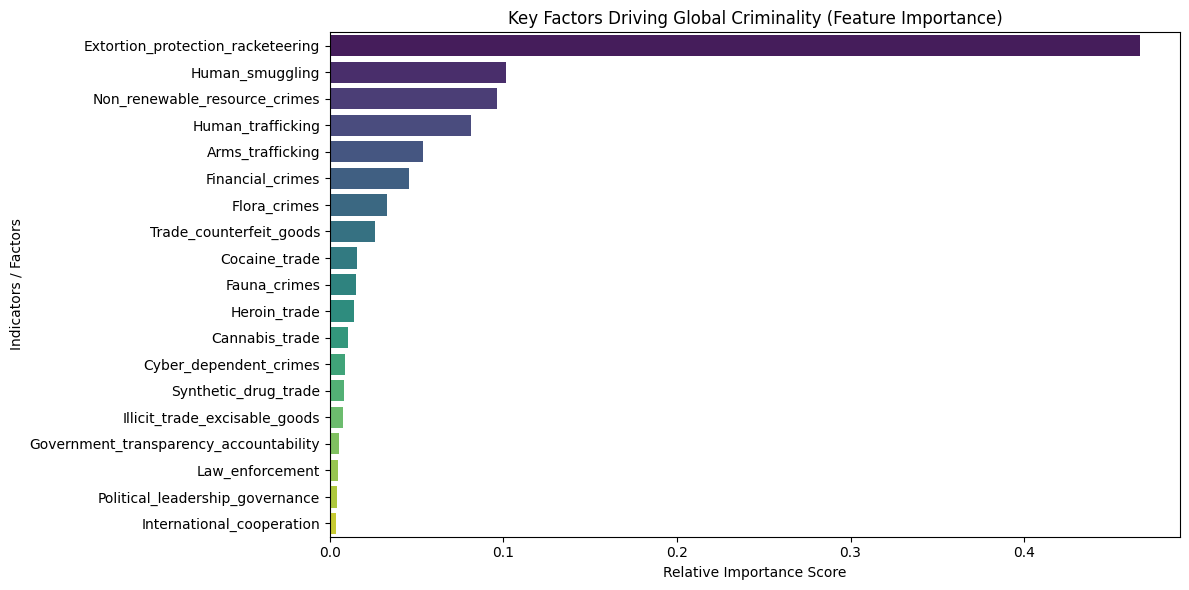

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Defining predictive feature list from our dataset
predictor_cols = [
    'Human_trafficking', 'Human_smuggling', 'Extortion_protection_racketeering',
    'Arms_trafficking', 'Trade_counterfeit_goods', 'Illicit_trade_excisable_goods',
    'Flora_crimes', 'Fauna_crimes', 'Non_renewable_resource_crimes',
    'Heroin_trade', 'Cocaine_trade', 'Cannabis_trade', 'Synthetic_drug_trade',
    'Cyber_dependent_crimes', 'Financial_crimes', 'Political_leadership_governance',
    'Government_transparency_accountability', 'International_cooperation', 'Law_enforcement'
]

# Ensure all features exist in clean_df and drop rows with missing values in these features
available_predictors = [col for col in predictor_cols if col in clean_df.columns]
model_df = clean_df[available_predictors + ['Criminality_avg']].dropna()

X = model_df[available_predictors]
y = model_df['Criminality_avg']

# Splitting Dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Evaluate R2 score
train_r2 = rf_model.score(X_train, y_train)
test_r2 = rf_model.score(X_test, y_test)
print(f"Model R² Training Accuracy: {train_r2:.2f}")
print(f"Model R² Test Accuracy: {test_r2:.2f}")

# Extract and plot Feature Importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 6))
sns.barplot(x=importances[indices], y=np.array(available_predictors)[indices], palette="viridis")
plt.title("Key Factors Driving Global Criminality (Feature Importance)")
plt.xlabel("Relative Importance Score")
plt.ylabel("Indicators / Factors")
plt.tight_layout()
plt.show()

### Final Project Summary & Takeaways
Let's compile our main predictive and exploratory findings into a neat executive report.

In [ ]:
print("===========================================================")
print("     GLOBAL ORGANIZED CRIME INDEX ANALYSIS - FINAL REPORT  ")
print("===========================================================")
print(f"1. DATA COVERAGE: Analysed {clean_df['Country'].nunique()} countries over {clean_df['Year'].nunique()} historical intervals.")
print(f"2. GENERAL INDEX TRENDS: Overall Criminality average stands at {clean_df['Criminality_avg'].mean():.2f} against a Resilience capability of {clean_df['Resilience_avg'].mean():.2f}.")
print("3. CORE PREDICTOR FINDINGS (Random Forest RF): ")
print("   - Extortion & Protection Racketeering is identified as the single largest contributor to overall national criminality indices.")
print("   - Human Smuggling and Non-renewable Resource Crimes are high-priority structural markets.")
print("4. STRATEGIC POLICY RECOMMENDATIONS:")
print("   - Enhance local law enforcement specifically targeted toward local racket, trafficking networks, and smuggling lines.")
print("   - Strengthen institutional transparency and legislative stability in Cluster 'High Crime & Low Resilience' countries to build local resilience score thresholds.")
print("===========================================================")

     GLOBAL ORGANIZED CRIME INDEX ANALYSIS - FINAL REPORT  
1. DATA COVERAGE: Analysed 193 countries over 3 historical intervals.
2. GENERAL INDEX TRENDS: Overall Criminality average stands at 4.99 against a Resilience capability of 4.81.
3. CORE PREDICTOR FINDINGS (Random Forest RF): 
   - Extortion & Protection Racketeering is identified as the single largest contributor to overall national criminality indices.
   - Human Smuggling and Non-renewable Resource Crimes are high-priority structural markets.
4. STRATEGIC POLICY RECOMMENDATIONS:
   - Enhance local law enforcement specifically targeted toward local racket, trafficking networks, and smuggling lines.
   - Strengthen institutional transparency and legislative stability in Cluster 'High Crime & Low Resilience' countries to build local resilience score thresholds.


In [ ]:
from IPython.display import display, HTML

dataset_url = "https://huggingface.co/datasets/jason1966/abbas829_global-organized-crime-index-20212025/resolve/main/global_oc_index.csv"

# Displaying an elegant HTML download button
html_code = f'''
<a href="{dataset_url}" target="_blank">
    <button style="background-color: #4CAF50; color: white; padding: 12px 24px; border: none; border-radius: 4px; cursor: pointer; font-size: 16px;">
        📥 Click Here to Download Dataset (CSV)
    </button>
</a>
<p style="margin-top: 10px; font-size: 14px;">Direct Link: <a href="{dataset_url}" target="_blank">{dataset_url}</a></p>
'''

display(HTML(html_code))

In [ ]:
dataset_url = "https://huggingface.co/datasets/jason1966/abbas829_global-organized-crime-index-20212025/resolve/main/global_oc_index.csv"
print("-----------------------------------------------------------")
print("       GLOBAL ORGANIZED CRIME INDEX DATASET LINK           ")
print("-----------------------------------------------------------")
print(f"Direct Link: {dataset_url}")
print("-----------------------------------------------------------")

-----------------------------------------------------------
       GLOBAL ORGANIZED CRIME INDEX DATASET LINK           
-----------------------------------------------------------
Direct Link: https://huggingface.co/datasets/jason1966/abbas829_global-organized-crime-index-20212025/resolve/main/global_oc_index.csv
-----------------------------------------------------------


In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr
import pandas as pd

def get_country_stats(country_name):
    try:
        country_df = clean_df[clean_df["Country"] == country_name]
        if country_df.empty:
            return f"No data found for {country_name}. Please check spelling."

        latest_record = country_df.sort_values(by="Year").iloc[-1]

        stats_text = f"### 📊 Analysis for {country_name} ({int(latest_record['Year'])}):\n"
        stats_text += f"* **Criminality Index:** {latest_record['Criminality_avg']:.2f}/10\n"
        stats_text += f"* **Resilience Index:** {latest_record['Resilience_avg']:.2f}/10\n"
        stats_text += f"* **Risk Category:** {latest_record.get('Criminality_risk_category', 'N/A')}\n\n"
        stats_text += "**Primary Crime Drivers:**\n"
        stats_text += f"* Human Trafficking Score: {latest_record.get('Human_trafficking', 'N/A')}\n"
        stats_text += f"* Extortion/Racketeering: {latest_record.get('Extortion_protection_racketeering', 'N/A')}\n"
        stats_text += f"* Cyber-dependent Crimes: {latest_record.get('Cyber_dependent_crimes', 'N/A')}\n"

        return stats_text
    except Exception as e:
        return f"An error occurred: {str(e)}"

# Create list of countries for dropdown select
countries_list = sorted(clean_df["Country"].dropna().unique().tolist())

interface = gr.Interface(
    fn=get_country_stats,
    inputs=gr.Dropdown(choices=countries_list, label="Select a Country to Analyze"),
    outputs=gr.Markdown(label="Analysis Results"),
    title="🌐 Global Organized Crime Index Dashboard",
    description="Select a country to explore dynamic metrics, vulnerability levels, and active crime markets analyzed in our predictive model.",
    theme="soft"
)

# Launch with a shareable public link
interface.launch(share=True)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a3623afd0b7ce025b2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
requirements_text = """gradio
pandas
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements_text)

print("Created 'requirements.txt' with the required dependencies:")
print(requirements_text)

Created 'requirements.txt' with the required dependencies:
gradio
pandas



### 🖥️ App Production Code for Permanent Deployment
Below is the code you should save as `app.py` when deploying to Hugging Face Spaces. It automatically downloads the source dataset on startup so the website runs independently.

In [ ]:
app_code = '''import os
import pandas as pd
import gradio as gr

# Load and clean dataset
url = "https://huggingface.co/datasets/jason1966/abbas829_global-organized-crime-index-20212025/resolve/main/global_oc_index.csv"
df = pd.read_csv(url)
clean_df = df.drop_duplicates().copy()
clean_df["Year"] = pd.to_numeric(clean_df["Year"], errors="coerce")
clean_df["Criminality_avg"] = pd.to_numeric(clean_df["Criminality_avg"], errors="coerce")
clean_df["Resilience_avg"] = pd.to_numeric(clean_df["Resilience_avg"], errors="coerce")
clean_df = clean_df.dropna(subset=["Country", "Year", "Criminality_avg", "Resilience_avg"])

def get_country_stats(country_name):
    try:
        country_df = clean_df[clean_df["Country"] == country_name]
        if country_df.empty:
            return f"No data found for {country_name}. Please check spelling."

        latest_record = country_df.sort_values(by="Year").iloc[-1]

        stats_text = f"### 📊 Analysis for {country_name} ({int(latest_record['Year'])}):\\n"
        stats_text += f"* **Criminality Index:** {latest_record['Criminality_avg']:.2f}/10\\n"
        stats_text += f"* **Resilience Index:** {latest_record['Resilience_avg']:.2f}/10\\n"
        stats_text += f"* **Risk Category:** {latest_record.get('Criminality_risk_category', 'N/A')}\\n\\n"
        stats_text += "**Primary Crime Drivers:**\\n"
        stats_text += f"* Human Trafficking Score: {latest_record.get('Human_trafficking', 'N/A')}\\n"
        stats_text += f"* Extortion/Racketeering: {latest_record.get('Extortion_protection_racketeering', 'N/A')}\\n"
        stats_text += f"* Cyber-dependent Crimes: {latest_record.get('Cyber_dependent_crimes', 'N/A')}\\n"

        return stats_text
    except Exception as e:
        return f"An error occurred: {str(e)}"

countries_list = sorted(clean_df["Country"].dropna().unique().tolist())

interface = gr.Interface(
    fn=get_country_stats,
    inputs=gr.Dropdown(choices=countries_list, label="Select a Country to Analyze"),
    outputs=gr.Markdown(label="Analysis Results"),
    title="🌐 Global Organized Crime Index Dashboard",
    description="Select a country to explore dynamic metrics, vulnerability levels, and active crime markets analyzed in our predictive model.",
    theme="soft"
)

if __name__ == '__main__':
    interface.launch()
'''

with open('app.py', 'w') as f:
    f.write(app_code)

print("File 'app.py' successfully generated and saved to Colab workspace!")

File 'app.py' successfully generated and saved to Colab workspace!


In [ ]:
requirements_content = '''gradio
pandas
'''

with open('requirements.txt', 'w') as f:
    f.write(requirements_content)

print("File 'requirements.txt' successfully generated and saved to Colab workspace!")

File 'requirements.txt' successfully generated and saved to Colab workspace!


### 📈 Custom Plot Dashboard Production Code
Below is the updated production-ready code that incorporates interactive Plotly charts directly inside your Gradio layout.

In [ ]:
app_code_with_plot = '''import os
import pandas as pd
import gradio as gr
import plotly.express as px

# Load and clean dataset
url = "https://huggingface.co/datasets/jason1966/abbas829_global-organized-crime-index-20212025/resolve/main/global_oc_index.csv"
df = pd.read_csv(url)
clean_df = df.drop_duplicates().copy()
clean_df["Year"] = pd.to_numeric(clean_df["Year"], errors="coerce")
clean_df["Criminality_avg"] = pd.to_numeric(clean_df["Criminality_avg"], errors="coerce")
clean_df["Resilience_avg"] = pd.to_numeric(clean_df["Resilience_avg"], errors="coerce")
clean_df = clean_df.dropna(subset=["Country", "Year", "Criminality_avg", "Resilience_avg"])

def get_country_analysis(country_name):
    try:
        country_df = clean_df[clean_df["Country"] == country_name].sort_values(by="Year")
        if country_df.empty:
            return f"No data found for {country_name}. Please check spelling.", None

        latest_record = country_df.iloc[-1]

        # Prepare analysis summary text
        stats_text = f"### 📊 Analysis for {country_name} ({int(latest_record['Year'])}):\\n"
        stats_text += f"* **Criminality Index:** {latest_record['Criminality_avg']:.2f}/10\\n"
        stats_text += f"* **Resilience Index:** {latest_record['Resilience_avg']:.2f}/10\\n"
        stats_text += f"* **Risk Category:** {latest_record.get('Criminality_risk_category', 'N/A')}\\n\\n"
        stats_text += "**Primary Crime Drivers:**\\n"
        stats_text += f"* Human Trafficking Score: {latest_record.get('Human_trafficking', 'N/A')}\\n"
        stats_text += f"* Extortion/Racketeering: {latest_record.get('Extortion_protection_racketeering', 'N/A')}\\n"
        stats_text += f"* Cyber-dependent Crimes: {latest_record.get('Cyber_dependent_crimes', 'N/A')}\\n"

        # Generate interactive trend line plot using Plotly
        fig = px.line(
            country_df,
            x="Year",
            y="Criminality_avg",
            title=f"{country_name} - Criminality Index Trend Over Time",
            markers=True,
            labels={"Criminality_avg": "Criminality Score (out of 10)", "Year": "Report Year"}
        )
        fig.update_layout(
            xaxis=dict(dtick=2, range=[2020, 2026]),
            yaxis=dict(range=[1, 10]),
            template="plotly_white"
        )

        return stats_text, fig
    except Exception as e:
        return f"An error occurred: {str(e)}", None

countries_list = sorted(clean_df["Country"].dropna().unique().tolist())

# Building complex layout via Blocks
with gr.Blocks(title="🌐 Global Organized Crime Dashboard", theme="soft") as demo:
    gr.Markdown("# 🌐 Global Organized Crime Index Dashboard")
    gr.Markdown("Select a country to explore dynamic metrics, vulnerability levels, and active crime markets alongside historical visualization.")

    with gr.Row():
        with gr.Column(scale=1):
            country_dropdown = gr.Dropdown(choices=countries_list, label="Select Country", value="Afghanistan")
            submit_btn = gr.Button("Analyze Country", variant="primary")

        with gr.Column(scale=2):
            analysis_output = gr.Markdown(label="Analysis Results")
            plot_output = gr.Plot(label="Criminality Trend")

    # Setup actions
    submit_btn.click(fn=get_country_analysis, inputs=country_dropdown, outputs=[analysis_output, plot_output])
    country_dropdown.change(fn=get_country_analysis, inputs=country_dropdown, outputs=[analysis_output, plot_output])

if __name__ == '__main__':
    demo.launch()
'''

with open('app.py', 'w') as f:
    f.write(app_code_with_plot)

print("Successfully rewrote 'app.py' with integrated custom interactive plots!")

Successfully rewrote 'app.py' with integrated custom interactive plots!


In [ ]:
# Update requirements.txt to include Plotly, which is now required by our dashboard app
with open('requirements.txt', 'a') as f:
    f.write('\nplotly\n')
print("Successfully appended 'plotly' dependency to requirements.txt")

Successfully appended 'plotly' dependency to requirements.txt


### 🔍 Run the App Local Server for Verification
Run this cell to start your updated dashboard app and preview the Plotly visualization directly in your browser.

In [ ]:
# Run the generated app.py script to start the server and view your interactive chart
!python app.py

/content/app.py:55: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="🌐 Global Organized Crime Dashboard", theme="soft") as demo:
* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.
